# Highlights

> Five findings about keeping large teams of language-model agents effective and safe, each with its figure redrawn from the saved per-seed results.

Teams of Claude Haiku 5.5 agents play a clue board. Every subtask's answer is fixed by two clues held by different agents, so no agent can solve one alone, and sharing a clue costs the sharer a turn. The experiments add one mechanism at a time, each under an analysis plan frozen and committed before its runs. The full write-up is the preprint [*Guards, Squads and Incentives*](https://github.com/Positron00/explRL/blob/main/paper/main.pdf); a companion preprint, [*Simulate First?*](https://github.com/Positron00/explRL/blob/main/paper2/main.pdf), scores what cheap rule-agent simulations predicted before each run.

This page redraws the figures from `data/highlights/highlights.json`, a 40 kB extract of the saved runs written by `tools/figures.py`; the raw results, the API response caches and the trained adapters stay out of the repository. Points and bars are means; error bars are one standard error over seeds (or held-out boards); an asterisk marks p < 0.05 in a two-sided exact test against the stated reference, uncorrected. The preprints give the pre-registered tests, with Holm correction.

In [ ]:
import json
from pathlib import Path

import numpy as np
from explRL.figs_rl import fixes, incentives
from explRL.figs_team import SCALE_ARMS, guards, guardsScale, signP, trend, trustScale

In [ ]:
H = json.loads(Path('../data/highlights/highlights.json').read_text())

## 1. Verification works as an assigned role

A quarter of the agents are scripted liars, and every clue is dealt to two agents. *Guards*, as many as there are liars, are told to post, confirm and contest clues and never to solve. With no access to the truth, guards protected the team better than any other defence, including a public record of how often each agent's earlier clues were true, which needs the true answers, and they cut the share of answers built on lies. A board that only displays how many agents agree on each value helped no more than a one-sentence instruction.

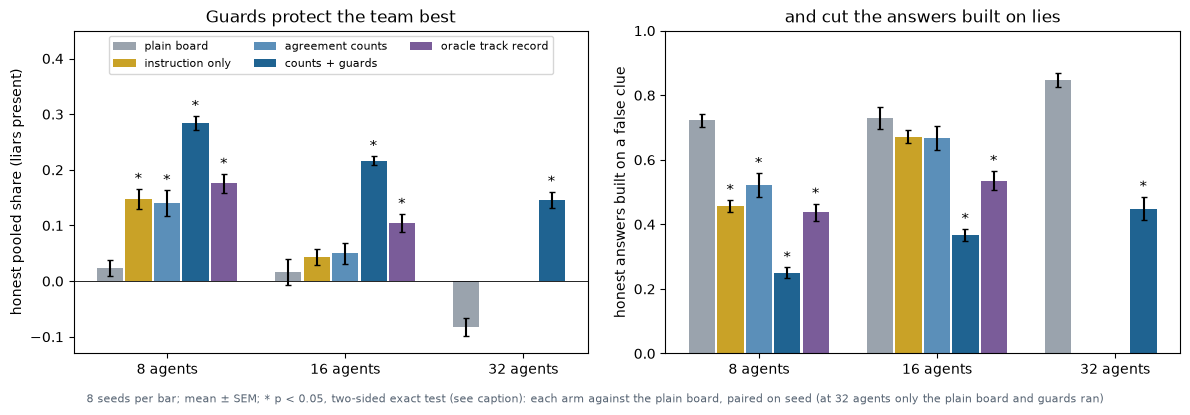

In [ ]:
guards(H['guards']);

## 2. Splitting a large team makes verification scale

On one board the guards' advantage over the plain board shrank as teams grew: a guard can contest only the clues it holds, about two in five, and in larger teams lies about the other clues caused more wrong answers (0.64 per lie at 8 agents, 1.49 at 64), so guards recovered 81% of the liars' damage at 8 agents but 60% at 32. Squads of eight, each with its own guards and subtasks, kept the advantage instead: it rose from 16 to 32 agents and held at 64, so their lead over one board widened with team size. The legend gives each design's trend over team size: the mean of each seed's slope over log2 of the number of agents, per doubling, with its two-sided exact sign-flip p (descriptive). Only the guards' decline and the squads' rise are significant. The check below recomputes these from the per-seed data:

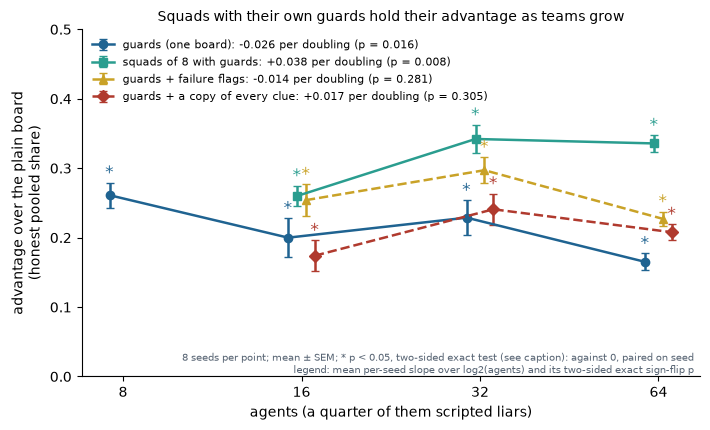

In [ ]:
guardsScale(H['guardsScale']);

In [ ]:
G, names = H['guardsScale'], {a: lab for a, lab, *_ in SCALE_ARMS}
for N, d in sorted(G['colonyGuards'].items(), key=lambda t: int(t[0])):
    v = list(d.values())
    print(f'guards at {N:>2} agents: ahead in {sum(x > 0 for x in v)} of {len(v)} seeds, mean {np.mean(v):+.3f}, two-sided exact p = {signP(v):.4f}')
for arm, d in G.items():
    b, p = trend(d)
    print(f"{names[arm]}, {'-'.join(sorted(d, key=int))} agents: {b:+.3f} per doubling, two-sided exact p = {p:.4f}")
rose = sum(G['squads']['64'][s] > G['squads']['16'][s] for s in G['squads']['16'])
print(f"squads: advantage higher at 64 agents than at 16 in {rose} of {len(G['squads']['16'])} seeds")

guards at  8 agents: ahead in 8 of 8 seeds, mean +0.261, two-sided exact p = 0.0078
guards at 16 agents: ahead in 8 of 8 seeds, mean +0.200, two-sided exact p = 0.0078
guards at 32 agents: ahead in 8 of 8 seeds, mean +0.229, two-sided exact p = 0.0078
guards at 64 agents: ahead in 8 of 8 seeds, mean +0.165, two-sided exact p = 0.0078
guards (one board), 8-16-32-64 agents: -0.026 per doubling, two-sided exact p = 0.0156
squads of 8 with guards, 16-32-64 agents: +0.038 per doubling, two-sided exact p = 0.0078
guards + failure flags, 16-32-64 agents: -0.014 per doubling, two-sided exact p = 0.2812
guards + a copy of every clue, 16-32-64 agents: +0.017 per doubling, two-sided exact p = 0.3047
squads: advantage higher at 64 agents than at 16 in 8 of 8 seeds


## 3. Larger teams are more gullible

With one holder per clue and a quarter of the agents liars, the share of honest answers built on a false clue rose with team size for Claude agents but not for rule agents (right). Replaying every turn from the response cache showed why: lies were no more visible in larger teams, but once a liar had posted a clue, agents treated it as settled. Two fixes tested at four agents kept their effect as teams grew (left): a *track record* beside each clue, showing how often its sender's earlier clues were true, won back 22-32% of the liars' damage at every size, while a *request board*, on which an agent spends a turn asking teammates for missing clues, made the team pool less of what it knew, by about the same amount at every size (it cost the asker a turn).

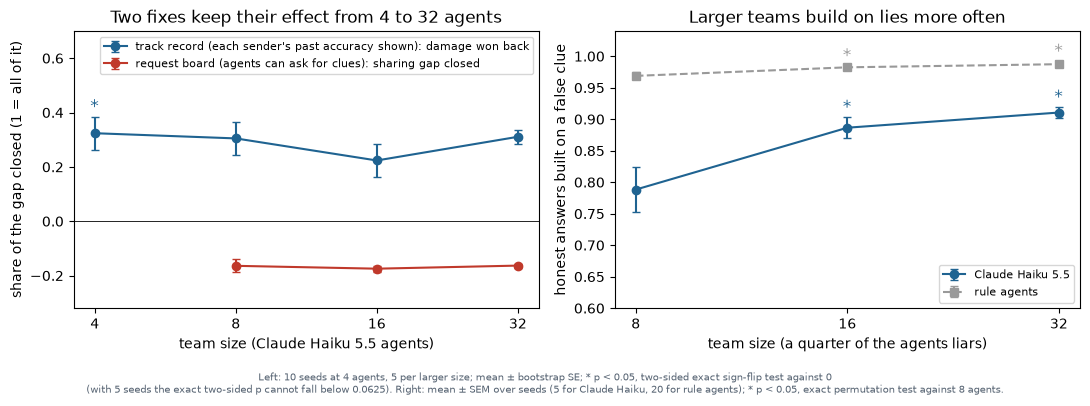

In [ ]:
trustScale(H['trust']);

## 4. Individual reward teaches guessing; a wrong-answer penalty stops it

Copies of Qwen2.5-3B-Instruct share one LoRA adapter and are trained with group-relative policy gradients from a warm start that imitates a rule agent. Each row is one training run, evaluated on 15 held-out boards against the warm start. The rewards: *individual* (an agent's own points), *team* (the team's mean), *credit* (the solver keeps half and the agents whose clues it used share the rest), *individual + penalty* (a wrong answer costs 3 points in training instead of 0.5, so guessing stops paying), and *credit, per-turn + penalty* (credit reward with the same penalty, assigned turn by turn). Under individual reward the copies stopped sharing and guessed. The penalty stopped the guessing in every run, but its effect on sharing varied from run to run, so we do not claim it restores cooperation. Offered the guard role without an assignment, no Claude agent took it, and team-reward training did not make roles emerge.

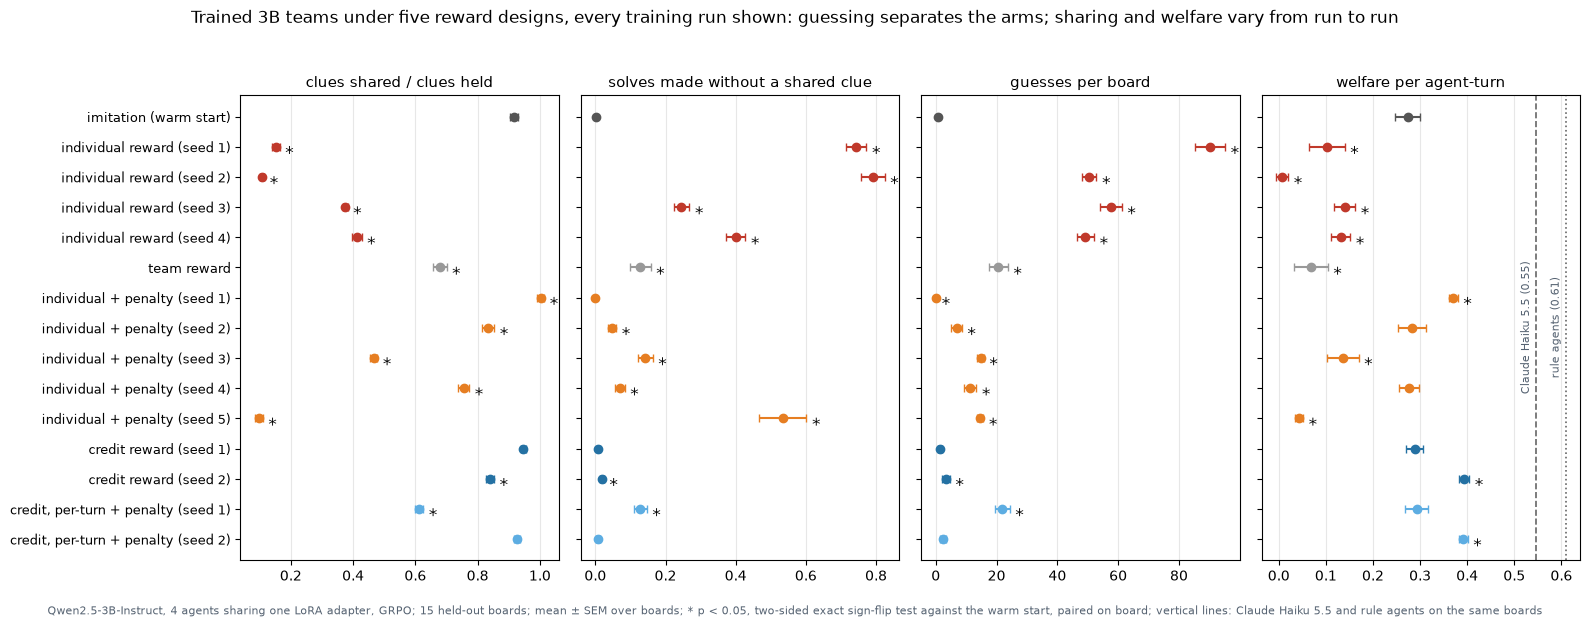

In [ ]:
incentives(H['incentives']);

## 5. Move information; do not add work

Each fix against its baseline at four agents (eight where marked): the share of the gap to the ceiling closed, or of a liar's damage recovered. On the clue board, a *request board* lets an agent spend a turn asking for missing clues, a *clue table* lists the clues posted so far for each subtask, *share first* tells agents to post every clue they hold before working on their own, a *track record* shows each sender's past accuracy, a *check action* spends a turn to learn privately whether a clue is true, and a *warning* says a teammate may lie. In a four-agent hidden-profile vote, *facts first* allows only facts in the first round, a *fact table* lists the facts posted so far, and *speak up* asks agents to share what others seem to lack; in the *lone dissenter* variant one member also holds a decisive fact. Fixes that move or certify information at no cost in turns helped; those that add work to every agent's turn did not.

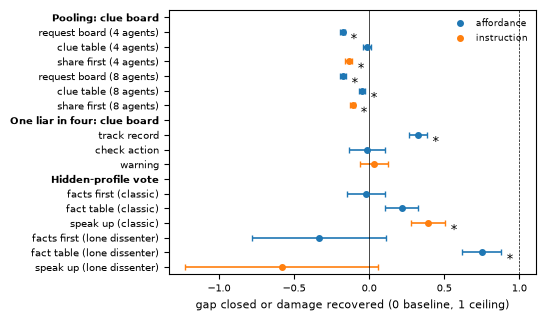

In [ ]:
fixes(H['fixes'], paper=True);

## Reproduce

`python tools/figures.py .` rebuilds `data/highlights/highlights.json` and every figure from `results/multiagent/`, which is kept out of git. The runs and their frozen plans are in the phase notebooks:

- guards at 8 and 16 agents: [demo_colony](demo_colony.ipynb); at 32 and 64 agents: [colony32](colony32.ipynb) and [colony64](colony64.ipynb)
- squads and the other design changes: [colony4](colony4.ipynb) and [colony4_report](colony4_report.ipynb); at 32 agents: [colony4b](colony4b.ipynb)
- replays of the guard boards and of the gullible teams: [colony_trace](colony_trace.ipynb) and [demo_liar](demo_liar.ipynb)
- fixes at four agents and as teams grow: [demo_fix](demo_fix.ipynb) and [demo_trust](demo_trust.ipynb)
- training: [demo_rl16](demo_rl16.ipynb), [demo_rl17](demo_rl17.ipynb) and [demo_rl18](demo_rl18.ipynb)

Every API reply is cached, so a rerun with the caches reproduces each row byte for byte at no cost.